# physim — mini Simscape-style 1D physical network simulator

Every **domain** has an *across* variable at **nodes** (voltage `V`, angular speed `ω`, temperature `T`)
and a *through* variable flowing through **components** between nodes (current `I`, torque `τ`, heat flow `q̇`).
Grounded nodes are fixed at 0. At every free node, the sum of through-variables into the node is zero (KCL/KTL-style conservation).

Each fixed step `h` solves the implicit trapezoidal system with `scipy.optimize.root` (Newton, warm-started),
then commits component states. Components can publish values into a shared `context` dict (one-step delay)
to couple domains — e.g. copper loss `P_loss::Ra` feeding a `HeatSource`.

This notebook runs the three demo systems plus a thermal/cross-domain example.

## Demo 1 — RLC step response (electrical)

12 V step into a series R = 0.5 Ω, L = 10 mH, C = 1 mF. Compared against the exact underdamped response
`vc(t) = V(1 − e^(−αt)(cos ωd t + (α/ωd) sin ωd t))`.

peak |error| vs exact = 0.0337 V  (acceptance < 0.05 V)


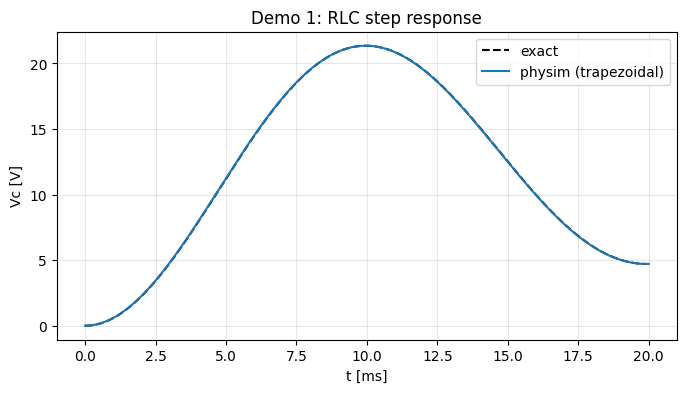

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from physim import Network, VoltageSource, Resistor, Inductor, Capacitor

net = Network()
net.add_node("g", "electrical", ground=True)
net.add_node("a", "electrical")   # source / R
net.add_node("b", "electrical")   # R / L
net.add_node("c", "electrical")   # L / C  <- vc is measured here
net.add(VoltageSource("src", "a", "g", 12.0))
net.add(Resistor("R", "a", "b", 0.5))
net.add(Inductor("L", "b", "c", 10e-3))
net.add(Capacitor("C", "c", "g", 1e-3))

h, t_end = 20e-6, 20e-3
ts, recs = net.run(t_end, h)
t = np.array(ts)
vc = np.array([r[1]["c"] for r in recs])

V, R, L, C = 12.0, 0.5, 10e-3, 1e-3
alpha = R / (2 * L)
wd = np.sqrt(1 / (L * C) - alpha**2)
vc_exact = V * (1 - np.exp(-alpha * t) * (np.cos(wd * t) + (alpha / wd) * np.sin(wd * t)))
print(f"peak |error| vs exact = {np.max(np.abs(vc - vc_exact)):.4f} V  (acceptance < 0.05 V)")

plt.figure(figsize=(8, 4))
plt.plot(t * 1e3, vc_exact, "k--", lw=1.5, label="exact")
plt.plot(t * 1e3, vc, label="physim (trapezoidal)")
plt.xlabel("t [ms]"); plt.ylabel("Vc [V]"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Demo 1: RLC step response"); plt.show()

## Demo 2 — DC motor drive, steady state (electrical ↔ rotational)

400 V battery with internal resistance Rb = 0.05 Ω drives an ideal DC machine (k = 0.8) coupled to
a flywheel J = 1.5 kg·m² with viscous damper b = 0.02. An opposing load torque of −15 N·m is applied from t = 1 s.
Analytic steady state: **I ≈ 31.20 A, ω ≈ 498 rad/s**.

at t=5 s:  I = 31.20 A (analytic 31.20),  w = 498.05 rad/s (analytic 498)


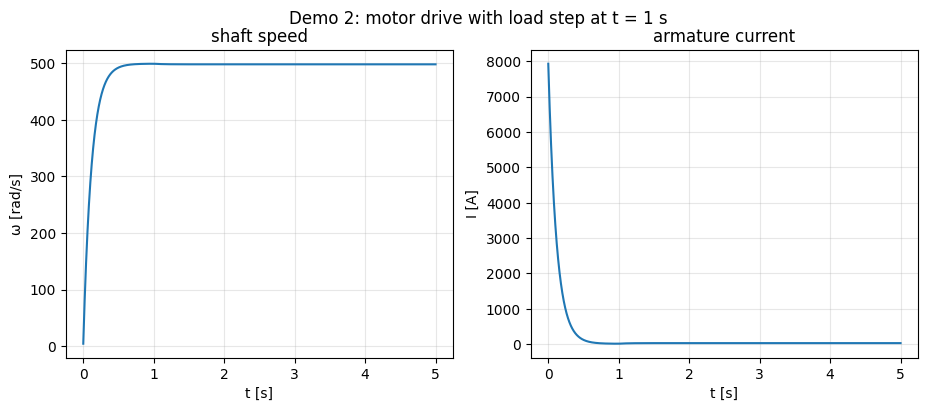

In [2]:
from physim import DCMachine, Inertia, Damper, TorqueSource

net = Network()
net.add_node("gnd", "electrical", ground=True)
net.add_node("a", "electrical")    # battery terminal
net.add_node("b", "electrical")    # machine terminal
net.add_node("rg", "rotational", ground=True)
net.add_node("sh", "rotational")   # shaft
net.add(VoltageSource("batt", "a", "gnd", 400.0))
net.add(Resistor("Rb", "a", "b", 0.05))
net.add(DCMachine("m", "b", "gnd", "sh", "rg", k=0.8))
net.add(Inertia("J", "sh", 1.5))
net.add(Damper("b", "sh", "rg", 0.02))
net.add(TorqueSource("load", "sh", lambda t: -15.0 if t >= 1.0 else 0.0))  # negative = load

ts, recs = net.run(5.0, 2e-3)
t = np.array(ts)
I = np.array([r[2]["m"]["I"] for r in recs])
w = np.array([r[2]["J"]["w"] for r in recs])
print(f"at t=5 s:  I = {I[-1]:.2f} A (analytic 31.20),  w = {w[-1]:.2f} rad/s (analytic 498)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, w); ax[0].set(xlabel="t [s]", ylabel="ω [rad/s]", title="shaft speed"); ax[0].grid(alpha=0.3)
ax[1].plot(t, I); ax[1].set(xlabel="t [s]", ylabel="I [A]", title="armature current"); ax[1].grid(alpha=0.3)
fig.suptitle("Demo 2: motor drive with load step at t = 1 s"); plt.show()

## Demo 3 — Regenerative braking

Same machine, but the battery voltage steps down: `V(t) = 400 V (t<8 s) → 250 V (8≤t<12 s) → 0 V`.
When the back-EMF `kω` exceeds the bus voltage, the armature current reverses and the bus absorbs energy.
We integrate the negative bus power and compare it with the flywheel kinetic energy lost (reference: ~83 kJ
returned of ~186 kJ lost, ≈ 45%).

energy returned to bus = 83.2 kJ
flywheel KE lost       = 186.0 kJ   (recovery 44.7 %)


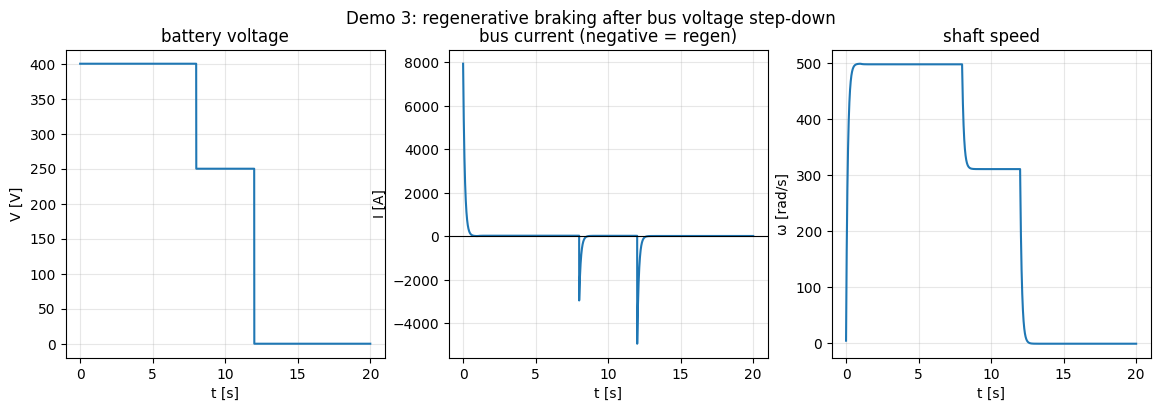

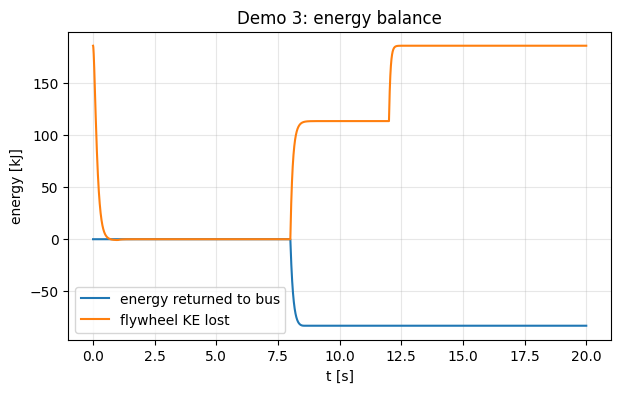

In [3]:
V = lambda t: 400.0 if t < 8.0 else (250.0 if t < 12.0 else 0.0)

net = Network()
net.add_node("gnd", "electrical", ground=True)
net.add_node("a", "electrical")
net.add_node("b", "electrical")
net.add_node("rg", "rotational", ground=True)
net.add_node("sh", "rotational")
net.add(VoltageSource("batt", "a", "gnd", V))
net.add(Resistor("Rb", "a", "b", 0.05))
net.add(DCMachine("m", "b", "gnd", "sh", "rg", k=0.8))
net.add(Inertia("J", "sh", 1.5))
net.add(Damper("b", "sh", "rg", 0.02))
net.add(TorqueSource("load", "sh", lambda t: -15.0 if t >= 1.0 else 0.0))

ts, recs = net.run(20.0, 2e-3)
t = np.array(ts)
I_bus = np.array([r[2]["Rb"]["I"] for r in recs])          # current delivered by battery to the bus
Vb = np.array([r[2]["batt"]["V"] for r in recs])
P_bus = Vb * I_bus                                          # >0 motoring, <0 regenerating
w = np.array([r[2]["J"]["w"] for r in recs])

e_returned = -np.trapz(np.minimum(P_bus, 0.0), t)
i8 = int(np.searchsorted(t, 8.0))
ke_lost = 0.5 * 1.5 * (w[i8]**2 - w[-1]**2)
print(f"energy returned to bus = {e_returned/1e3:.1f} kJ")
print(f"flywheel KE lost       = {ke_lost/1e3:.1f} kJ   (recovery {100*e_returned/ke_lost:.1f} %)")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(t, Vb); ax[0].set(xlabel="t [s]", ylabel="V [V]", title="battery voltage"); ax[0].grid(alpha=0.3)
ax[1].plot(t, I_bus); ax[1].axhline(0, color="k", lw=0.8); ax[1].set(xlabel="t [s]", ylabel="I [A]", title="bus current (negative = regen)"); ax[1].grid(alpha=0.3)
ax[2].plot(t, w); ax[2].set(xlabel="t [s]", ylabel="ω [rad/s]", title="shaft speed"); ax[2].grid(alpha=0.3)
fig.suptitle("Demo 3: regenerative braking after bus voltage step-down"); plt.show()

# Cumulative recovered energy vs remaining flywheel KE
ke = 0.5 * 1.5 * w**2
e_cum = -np.concatenate([[0], np.cumsum(0.5 * (np.minimum(P_bus, 0)[:-1] + np.minimum(P_bus, 0)[1:]) * np.diff(t))])
plt.figure(figsize=(7, 4))
plt.plot(t, -e_cum / 1e3, label="energy returned to bus")
plt.plot(t, (ke[i8] - ke) / 1e3, label="flywheel KE lost")
plt.xlabel("t [s]"); plt.ylabel("energy [kJ]"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Demo 3: energy balance"); plt.show()

## Demo 4 — Thermal step + cross-domain coupling

(a) 10 W into a thermal mass C = 800 J/K with convection Rth = 0.8 K/W to ambient, vs the exact
`T(t) = P·Rth·(1 − e^(−t/RC))`.
(b) A 100 V bus → armature resistance Ra = 0.2 Ω → DC machine (k = 0.5) → flywheel J with friction.
The resistor publishes `P_loss::Ra` into the shared context; a `HeatSource` reads it (one-step delay)
and injects it into a thermal mass. Steady-state loss ≈ 0.128 W (≈ 0.13 W).

(a) thermal peak |error| = 0.00312 K  (acceptance < 0.01 K)


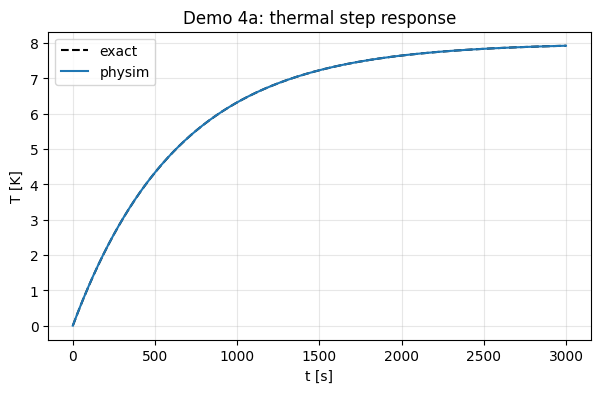

(b) steady P_loss::Ra = 0.1276 W  (analytic 0.128 W)
(b) max one-step-delay mismatch = 1.00e-04 W


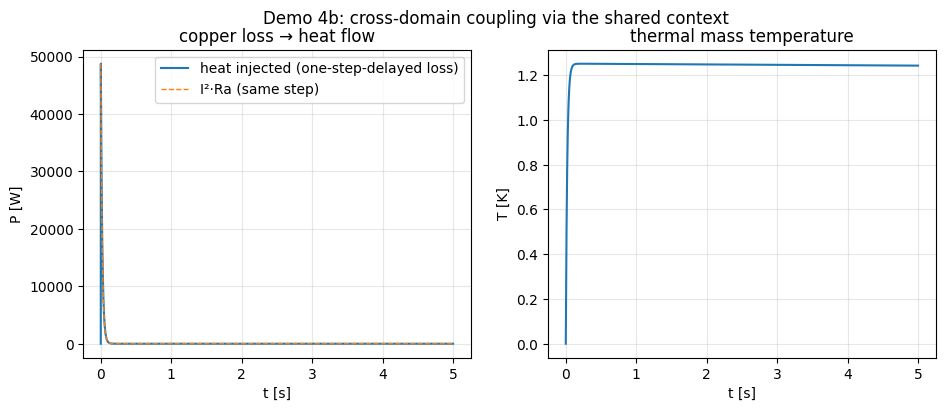

In [4]:
from physim import ThermalMass, ThermalResistor, HeatSource

# (a) thermal step
net = Network()
net.add_node("amb", "thermal", ground=True)
net.add_node("T1", "thermal")
net.add(HeatSource("q", "T1", 10.0))
net.add(ThermalMass("C", "T1", 800.0))
net.add(ThermalResistor("Rth", "T1", "amb", 0.8))
ts, recs = net.run(3000.0, 0.5)
t = np.array(ts)
T = np.array([r[1]["T1"] for r in recs])
T_exact = 10.0 * 0.8 * (1 - np.exp(-t / (800.0 * 0.8)))
print(f"(a) thermal peak |error| = {np.max(np.abs(T - T_exact)):.5f} K  (acceptance < 0.01 K)")
plt.figure(figsize=(7, 4))
plt.plot(t, T_exact, "k--", lw=1.5, label="exact")
plt.plot(t, T, label="physim")
plt.xlabel("t [s]"); plt.ylabel("T [K]"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Demo 4a: thermal step response"); plt.show()

# (b) cross-domain: copper loss -> heat
net = Network()
net.add_node("gnd", "electrical", ground=True)
net.add_node("a", "electrical")
net.add_node("b", "electrical")
net.add_node("rg", "rotational", ground=True)
net.add_node("sh", "rotational")
net.add_node("amb", "thermal", ground=True)
net.add_node("T1", "thermal")
net.add(VoltageSource("bus", "a", "gnd", 100.0))
net.add(Resistor("Ra", "a", "b", 0.2))
net.add(DCMachine("m", "b", "gnd", "sh", "rg", k=0.5))
net.add(Inertia("J", "sh", 0.05))
net.add(Damper("fric", "sh", "rg", 0.002))
net.add(ThermalMass("Cth", "T1", 800.0))
net.add(ThermalResistor("Rth", "T1", "amb", 0.8))
net.add(HeatSource("loss", "T1", lambda t, ctx: ctx.get("P_loss::Ra", 0.0)))

ts, recs = net.run(5.0, 1e-3)
t = np.array(ts)
I_ra = np.array([r[2]["Ra"]["I"] for r in recs])
q_heat = np.array([r[2]["loss"]["Q"] for r in recs])
T1 = np.array([r[1]["T1"] for r in recs])
print(f"(b) steady P_loss::Ra = {recs[-1][2]['Ra']['P_loss']:.4f} W  (analytic 0.128 W)")
print(f"(b) max one-step-delay mismatch = {np.max(np.abs(q_heat[1:] - 0.2 * I_ra[:-1]**2)):.2e} W")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, q_heat, label="heat injected (one-step-delayed loss)")
ax[0].plot(t, 0.2 * I_ra**2, "--", lw=1, label="I²·Ra (same step)")
ax[0].set(xlabel="t [s]", ylabel="P [W]", title="copper loss → heat flow"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(t, T1); ax[1].set(xlabel="t [s]", ylabel="T [K]", title="thermal mass temperature"); ax[1].grid(alpha=0.3)
fig.suptitle("Demo 4b: cross-domain coupling via the shared context"); plt.show()

## Build your own system in 6 lines

```python
from physim import Network, VoltageSource, Resistor, Capacitor
net = Network()
net.add_node("g", "electrical", ground=True)
net.add_node("a", "electrical")
net.add(VoltageSource("src", "a", "g", 5.0))
net.add(Resistor("R", "a", "g", 100.0)); net.add(Capacitor("C", "a", "g", 1e-6))
ts, recs = net.run(1e-3, 1e-6)   # recs[i] = (t, {node: across_value}, {comp: observe_dict})
```

See `README.md` for sign conventions and how to add your own components/domains.